# ML - Tugas 4

Jalankan seluruh sel secara berurutan. Gunakan dataset lokal jika tersedia, atau baca CSV langsung dari URL.

In [1]:
# -*- coding: utf-8 -*-
"""Tugas4 ML

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1jtJ1SVc8aVF7ZEybCLMc5O41NUo9RYIt
"""

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2, RFE
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay
)
print("Versi scikit-learn:", sklearn.__version__)

Versi scikit-learn: 1.9.1


In [2]:
from pathlib import Path

# Mendukung script Python dan notebook yang dijalankan dari folder proyek/pertemuan.
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
PROJECT_DIR = next(
    (p for p in (BASE_DIR, BASE_DIR.parent) if (p / "datasets").is_dir()),
    BASE_DIR.parent,
)

# Gunakan dataset lokal jika tersedia; jika tidak, baca langsung dari URL.
filename = PROJECT_DIR / "datasets" / "Titanic-Dataset.csv"
if not filename.is_file():
    filename = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(filename)
print("Ukuran dataset:", df.shape)
display(df.head())
print("Jumlah nilai kosong:")
print(df.isna().sum())
print("Distribusi target (0=tidak selamat, 1=selamat):")
print(df["Survived"].value_counts().sort_index())

Ukuran dataset: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Jumlah nilai kosong:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Distribusi target (0=tidak selamat, 1=selamat):
Survived
0    549
1    342
Name: count, dtype: int64


In [3]:
# Feature construction: membuat fitur baru.
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Identitas, tiket, dan Cabin tidak digunakan pada praktikum ini.
X = df.drop(columns=[
    "Survived", "PassengerId", "Name", "Ticket", "Cabin"
])
y = df["Survived"]

In [4]:
# 80% untuk latihan, 20% untuk pengujian.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Jumlah fitur:", X.shape[1])
print("Data train:", X_train.shape)
print("Data test :", X_test.shape)
print("Kelas train:", np.bincount(y_train))
print("Kelas test :", np.bincount(y_test))

fitur_numerik = [
    "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"
]
fitur_kategorikal = ["Sex", "Embarked"]
fitur_ordinal = ["Pclass"]

numerik = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
kategorikal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False))
])
ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[[1, 2, 3]],
        handle_unknown="use_encoded_value", unknown_value=-1
    ))
])
preprocessor = ColumnTransformer([
    ("num", numerik, fitur_numerik),
    ("cat", kategorikal, fitur_kategorikal),
    ("ord", ordinal, fitur_ordinal)
])
print("Preprocessor siap; belum dilatih.")

Jumlah fitur: 9
Data train: (712, 9)
Data test : (179, 9)
Kelas train: [439 273]
Kelas test : [110  69]
Preprocessor siap; belum dilatih.


Training selesai.
Jumlah fitur setelah encoding: 12
Accuracy train: 0.9831 (98.31%)
Accuracy test : 0.8045 (80.45%)
Gap           : 0.1787
Prediksi benar: 144 dari 179
               precision    recall  f1-score   support

Tidak selamat     0.8261    0.8636    0.8444       110
      Selamat     0.7656    0.7101    0.7368        69

     accuracy                         0.8045       179
    macro avg     0.7959    0.7869    0.7906       179
 weighted avg     0.8028    0.8045    0.8030       179



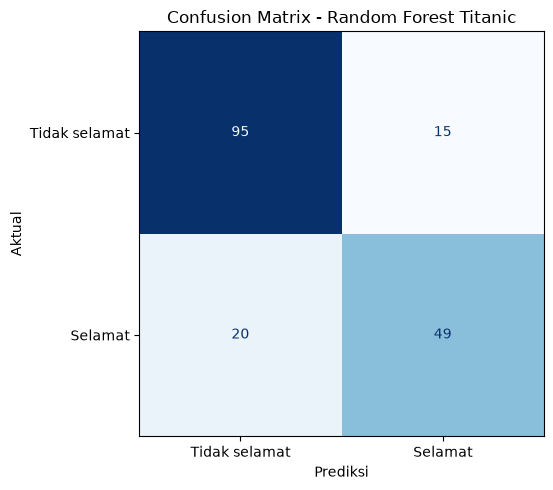

In [5]:
# Survived adalah kelas, maka gunakan Classifier.
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ))
])
pipeline.fit(X_train, y_train)
print("Training selesai.")
print("Jumlah fitur setelah encoding:", len(
    pipeline.named_steps["preprocessing"].get_feature_names_out()
))

y_pred_train = pipeline.predict(X_train)
y_pred = pipeline.predict(X_test)
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred)
print(f"Accuracy train: {acc_train:.4f} ({acc_train:.2%})")
print(f"Accuracy test : {acc_test:.4f} ({acc_test:.2%})")
print(f"Gap           : {acc_train - acc_test:.4f}")
print("Prediksi benar:", (y_test == y_pred).sum(),
      "dari", len(y_test))
print(classification_report(
    y_test, y_pred, target_names=["Tidak selamat", "Selamat"],
    digits=4, zero_division=0
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Tidak selamat", "Selamat"],
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion Matrix - Random Forest Titanic")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

In [6]:
# Gunakan preprocessing yang sudah fit pada train.
prep = pipeline.named_steps["preprocessing"]
X_train_encoded = prep.transform(X_train)
X_test_encoded = prep.transform(X_test)
nama_fitur = prep.get_feature_names_out()

# Chi-square mensyaratkan nilai nonnegatif.
# Scaling ini dipelajari hanya dari train.
scaler_seleksi = MinMaxScaler(clip=True)
X_train_fs = scaler_seleksi.fit_transform(X_train_encoded)
X_test_fs = scaler_seleksi.transform(X_test_encoded)

In [7]:
# Filter: pilih 5 fitur dengan skor chi-square tertinggi.
filter_model = SelectKBest(score_func=chi2, k=5)
filter_model.fit(X_train_fs, y_train)

SelectKBest(k=5, score_func=<function chi2 at 0x000002C8C9334930>)

In [8]:
# Wrapper: buang fitur bertahap sampai tersisa 5.
rfe_model = RFE(
    LogisticRegression(max_iter=2000, random_state=42),
    n_features_to_select=5
)
rfe_model.fit(X_train_fs, y_train)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...ndom_state=42)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",5
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,LogisticRegression,LogisticRegre...ndom_state=42)
n_features_ n_features_: intThe number of selected features.,int64,np.int64(5)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,12
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](12,)","[1,2,6,...,7,3,1]"


In [9]:
# Embedded: koefisien Lasso yang bukan nol dipertahankan.
lasso_model = Lasso(alpha=0.01, max_iter=10000)
lasso_model.fit(X_train_fs, y_train)
mask_fitur = {
    "SelectKBest": filter_model.get_support(),
    "RFE": rfe_model.get_support(),
    "Lasso": np.abs(lasso_model.coef_) > 1e-6
}
for nama, mask in mask_fitur.items():
    print()
    print(f"{nama} - {mask.sum()} fitur:")
    print(", ".join(nama_fitur[mask]))

hasil = [{
    "Metode": "Semua fitur", "Jumlah fitur": len(nama_fitur),
    "Accuracy train": acc_train, "Accuracy test": acc_test
}]
for nama, mask in mask_fitur.items():
    if not mask.any():
        print(nama, "tidak memilih fitur; ubah alpha Lasso.")
        continue
    model = RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
    # Seleksi memakai mask dari Cell 8; model memakai skala awal.
    model.fit(X_train_encoded[:, mask], y_train)
    hasil.append({
        "Metode": nama, "Jumlah fitur": int(mask.sum()),
        "Accuracy train": accuracy_score(
            y_train, model.predict(X_train_encoded[:, mask])
        ),
        "Accuracy test": accuracy_score(
            y_test, model.predict(X_test_encoded[:, mask])
        )
    })
hasil = pd.DataFrame(hasil)
hasil["Gap"] = hasil["Accuracy train"] - hasil["Accuracy test"]
display(hasil.round(4))


SelectKBest - 5 fitur:
num__IsAlone, cat__Sex_female, cat__Sex_male, cat__Embarked_C, ord__Pclass

RFE - 5 fitur:
num__Age, num__FamilySize, cat__Sex_female, cat__Sex_male, ord__Pclass

Lasso - 3 fitur:
cat__Sex_female, cat__Embarked_S, ord__Pclass


,Metode,Jumlah fitur,Accuracy train,Accuracy test,Gap
0,Semua fitur,12,0.9831,0.8045,0.1787
1,SelectKBest,5,0.8118,0.7877,0.0241
2,RFE,5,0.9157,0.7821,0.1336
3,Lasso,3,0.8160,0.7933,0.0227
